# Tuần 6 — M1 tinh chỉnh — YOLO26n, ảnh đầu vào 800

Giống M1, chỉ đổi kích thước ảnh đầu vào từ 640 lên 800 (`imgsz`) để xem vật thể nhỏ (face, helmet, head;
55% số hộp nhỏ hơn 32×32 pixel) có được phát hiện tốt hơn không. Các tham số khác giữ nguyên.
Kết quả đánh giá trên tập validation; tập test giữ lại để so sánh M0, M1, M2 cùng lúc ở tuần 7.

**Cách chạy (VS Code + tiện ích Google Colab):**
1. `Select Kernel` → `Colab` → `New Colab Server` → `GPU` → `T4`.
2. `Run All`. Ô gắn Google Drive mở hộp thoại: bấm `Connect to Google Drive`, **cấp quyền xong trong trình duyệt bằng đúng
   tài khoản Google đang đăng nhập Colab trong VS Code** (cho phép truy cập Drive) rồi mới quay lại bấm `Continue`.
   Nếu ô báo lỗi `Credentials propagation unsuccessful` thì chạy lại riêng ô đó. Notebook dừng ở ô này chứ không huấn
   luyện khi chưa gắn được Drive, để kết quả không bị mất nếu Colab ngắt.
3. Nếu Colab bị ngắt giữa chừng: chọn lại kernel Colab và `Run All` lần nữa. Notebook tự tải lại dữ liệu và **huấn luyện
   tiếp từ epoch cuối đã lưu** (`last.pt` trên Drive); nếu đã huấn luyện xong thì bỏ qua bước huấn luyện.
4. Xong: tải `M1_yolo26n_img800_results.zip` (trong `/content` hoặc `MyDrive/DATN/runs`) về, giải nén vào thư mục `runs/` của repo.

**Theo dõi tiến độ:** mỗi epoch in một dòng bắt đầu bằng `[M1_yolo26n_img800]` (thời gian, mất mát, mAP, Recall lớp vi phạm).
Auto Save của VS Code không lưu file khi output thay đổi liên tục (đang huấn luyện): bấm `Cmd+S` khi cần cập nhật
file notebook trên máy.

In [1]:
# Cấu hình: tham số huấn luyện còn lại giữ mặc định của Ultralytics; các giá trị dưới đây ghi rõ để tái lập
from pathlib import Path

RUN_NAME = "M1_yolo26n_img800"
MODEL = "yolo26n.pt"  # YOLO26n tiền huấn luyện trên COCO
EPOCHS, IMGSZ, BATCH = 100, 800, 16
PRIORITY = "person_no_helmet"  # lớp vi phạm, mục tiêu Recall ≥ 0,80

ROOT = Path("/content")
DATA_DIR = ROOT / "SHEL5K_processed"
DATA_YAML = DATA_DIR / "data.yaml"
ZIP_ID = "1yJzRS_zbwqPiHM0P5JmBkGXkkih-2xdA"  # data/SHEL5K_processed.zip trên Google Drive (chia sẻ công khai)
ZIP_MD5 = "40f58cafcb67aac310a6a5ee358178d8"
EXPECTED = {"train": (3522, 46550), "val": (751, 9955), "test": (727, 9929)}  # (ảnh, hộp) theo reports/preprocessing/summary.json

## 1. Kiểm tra GPU và cài thư viện

Giữ nguyên PyTorch có sẵn của Colab, chỉ cài Ultralytics đúng phiên bản dùng ở máy local.

In [2]:
import shutil, subprocess

assert shutil.which("nvidia-smi"), "Chưa có GPU: Select Kernel → Colab → New Colab Server → GPU → T4"
print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                     capture_output=True, text=True).stdout)

Tesla T4, 15360 MiB



In [3]:
%pip install -q ultralytics==8.4.164 gdown

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 38.3 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.7 MB/s eta 0:00:00


## 2. Gắn Google Drive

Kết quả huấn luyện (trọng số mỗi epoch, `results.csv`, biểu đồ) được ghi thẳng vào `MyDrive/DATN/runs` để không mất khi Colab ngắt phiên.

In [4]:
from google.colab import drive

# Lỗi "Credentials propagation unsuccessful": chạy lại ô này, cấp quyền xong trong trình duyệt rồi mới bấm Continue
drive.mount(str(ROOT / "drive"))
PROJECT = ROOT / "drive/MyDrive/DATN/runs"
PROJECT.mkdir(parents=True, exist_ok=True)
print("Lưu kết quả vào:", PROJECT)

Mounted at /content/drive
Lưu kết quả vào: /content/drive/MyDrive/DATN/runs


## 3. Tải và kiểm tra dữ liệu

Tải `SHEL5K_processed.zip` từ Google Drive, kiểm tra mã MD5 khớp với file tạo ở máy local rồi giải nén vào `/content`. Sau đó đếm lại số ảnh, số file nhãn, số hộp của từng tập và so với báo cáo tiền xử lý.

In [5]:
import hashlib, zipfile

zip_path = ROOT / "SHEL5K_processed.zip"
if not DATA_YAML.exists():
    if not zip_path.exists():
        import gdown
        gdown.download(id=ZIP_ID, output=str(zip_path), quiet=False)
    with open(zip_path, "rb") as f:
        md5 = hashlib.file_digest(f, "md5").hexdigest()
    assert md5 == ZIP_MD5, f"File zip khác bản gốc (MD5 {md5}): xóa {zip_path} rồi chạy lại ô này"
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(ROOT)

for split, (n_img, n_box) in EXPECTED.items():
    imgs = list((DATA_DIR / "images" / split).glob("*.png"))
    labels = list((DATA_DIR / "labels" / split).glob("*.txt"))
    boxes = sum(len(p.read_text().splitlines()) for p in labels)
    print(f"{split:5s}: {len(imgs)} ảnh, {len(labels)} file nhãn, {boxes} hộp")
    assert (len(imgs), len(labels), boxes) == (n_img, n_img, n_box), f"Tập {split} không khớp bản tiền xử lý"

Downloading...
From (original): https://drive.google.com/uc?id=1yJzRS_zbwqPiHM0P5JmBkGXkkih-2xdA
From (redirected): https://drive.google.com/uc?id=1yJzRS_zbwqPiHM0P5JmBkGXkkih-2xdA&confirm=t&uuid=48fec9be-a945-43ae-bb80-ded21d367088
To: /content/SHEL5K_processed.zip
100%|██████████| 1.04G/1.04G [00:16<00:00, 62.0MB/s]


train: 3522 ảnh, 3522 file nhãn, 46550 hộp
val  : 751 ảnh, 751 file nhãn, 9955 hộp
test : 727 ảnh, 727 file nhãn, 9929 hộp


## 4. Huấn luyện

Nếu trên Drive đã có `last.pt` của lần chạy trước thì huấn luyện tiếp (`resume=True`), không bắt đầu lại từ đầu. Sau mỗi epoch, hàm `log_epoch` in một dòng tiến độ và ghi thêm vào `epoch_log.csv` thời gian epoch, Recall và AP@0.5 của lớp `person_no_helmet` trên tập val (`results.csv` của Ultralytics chỉ có chỉ số trung bình 6 lớp).

In [6]:
import csv, os
import torch
from ultralytics import YOLO

# shortcut: chế độ "không tương tác" của Ultralytics (chỉ ảnh hưởng thanh tiến độ) cập nhật 60 s/lần thay vì liên tục,
# để Auto Save của VS Code lưu được file notebook trong lúc huấn luyện; không ảnh hưởng kết quả huấn luyện
os.environ["GITHUB_ACTIONS"] = "true"

def log_epoch(trainer):
    epoch, total = trainer.epoch + 1, trainer.epochs
    if epoch > total:  # Ultralytics gọi thêm một lần sau khi đánh giá best.pt
        return
    pri = next(r for r in trainer.validator.metrics.summary() if r["Class"] == PRIORITY)
    log = trainer.save_dir / "epoch_log.csv"
    new = not log.exists()
    with open(log, "a", newline="") as f:
        w = csv.writer(f)
        if new:
            w.writerow(["epoch", "seconds", "recall_priority", "ap50_priority"])
        w.writerow([epoch, round(trainer.epoch_time, 1), pri["Box-R"], pri["mAP50"]])
    m = trainer.metrics
    losses = " ".join(f"{k.split('/')[1].removesuffix('_loss')} {v:.3f}"
                      for k, v in trainer.label_loss_items(trainer.tloss, prefix="train").items())
    print(f"[{RUN_NAME}] epoch {epoch}/{total} | {trainer.epoch_time:.0f} s, còn ~{trainer.epoch_time * (total - epoch) / 60:.0f} phút"
          f" | loss {losses} | mAP50 {m['metrics/mAP50(B)']:.3f} mAP50-95 {m['metrics/mAP50-95(B)']:.3f}"
          f" | R {PRIORITY} {pri['Box-R']:.3f}", flush=True)

run_dir = PROJECT / RUN_NAME
last = run_dir / "weights" / "last.pt"
# Ultralytics ghi epoch = -1 vào last.pt khi đã huấn luyện xong
finished = last.exists() and torch.load(last, map_location="cpu", weights_only=False)["epoch"] == -1
if finished:
    print(f"{RUN_NAME} đã huấn luyện xong, dùng lại kết quả trong {run_dir}")
else:
    if last.exists():
        print("Huấn luyện tiếp từ", last)
    model = YOLO(last if last.exists() else MODEL)
    model.add_callback("on_fit_epoch_end", log_epoch)
    model.train(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
                project=str(PROJECT), name=RUN_NAME, exist_ok=True, resume=last.exists())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Huấn luyện tiếp từ /content/drive/MyDrive/DATN/runs/M1_yolo26n_img800/weights/last.pt
New https://pypi.org/project/ultralytics/8.4.183 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.164 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SHEL5K_processed/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=

## 5. Đường cong huấn luyện

Các hình đầu là mất mát trên tập train và val theo epoch; hình cuối là chỉ số trên tập val, đường nét đứt là mục tiêu (mAP@0.5 ≥ 0,85, Recall `person_no_helmet` ≥ 0,80).

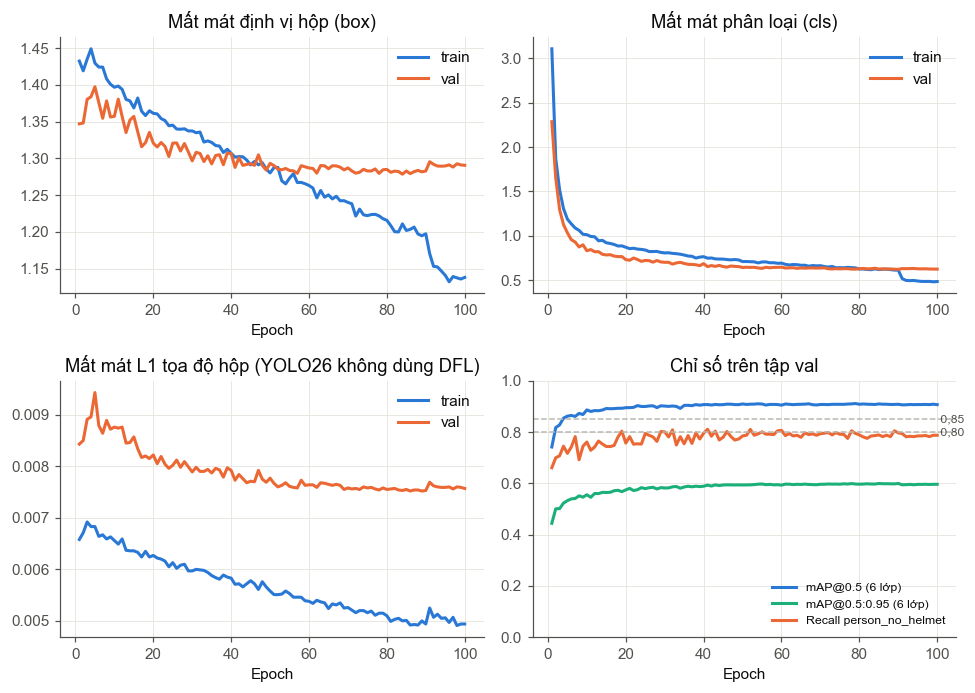

100 epoch, tổng thời gian huấn luyện 2.24 giờ


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

BLUE, ORANGE, AQUA, GRAY, INK, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#b9b8b2", "#0b0b0b", "#52514e", "#e6e5e0"
fonts = {f.name for f in font_manager.fontManager.ttflist}
STYLE = {  # chỉ áp cho hình này, không ảnh hưởng hình Ultralytics vẽ ở các ô sau
    "font.family": next((f for f in ("Arial", "Liberation Sans") if f in fonts), "DejaVu Sans"), "font.size": 10,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
}
TITLES = {"box_loss": "Mất mát định vị hộp (box)", "cls_loss": "Mất mát phân loại (cls)",
          "dfl_loss": "Mất mát phân phối biên (DFL)", "l1_loss": "Mất mát L1 tọa độ hộp (YOLO26 không dùng DFL)"}

res = pd.read_csv(run_dir / "results.csv").drop_duplicates("epoch", keep="last")  # epoch chạy lại khi resume
log = pd.read_csv(run_dir / "epoch_log.csv").drop_duplicates("epoch", keep="last")
loss_names = [c.split("/")[1] for c in res.columns if c.startswith("train/")]

with plt.rc_context(STYLE):
    rows = len(loss_names) // 2 + 1  # các ô mất mát + 1 ô chỉ số
    fig, axes = plt.subplots(rows, 2, figsize=(9, 3.2 * rows))
    axes = axes.ravel()
    for ax in axes[len(loss_names) + 1:]:
        ax.remove()
    for ax, name in zip(axes, loss_names):
        ax.plot(res["epoch"], res[f"train/{name}"], color=BLUE, lw=2, label="train")
        ax.plot(res["epoch"], res[f"val/{name}"], color=ORANGE, lw=2, label="val")
        ax.set(title=TITLES.get(name, name), xlabel="Epoch")
        ax.legend(frameon=False)
    ax = axes[len(loss_names)]
    ax.plot(res["epoch"], res["metrics/mAP50(B)"], color=BLUE, lw=2, label="mAP@0.5 (6 lớp)")
    ax.plot(res["epoch"], res["metrics/mAP50-95(B)"], color=AQUA, lw=2, label="mAP@0.5:0.95 (6 lớp)")
    ax.plot(log["epoch"], log["recall_priority"], color=ORANGE, lw=2, label=f"Recall {PRIORITY}")
    for y in (0.85, 0.80):
        ax.axhline(y, color=GRAY, lw=1, ls="--")
        ax.text(res["epoch"].max(), y, f" {y:.2f}".replace(".", ","), va="center", fontsize=8, color=INK2)
    ax.set(title="Chỉ số trên tập val", xlabel="Epoch", ylim=(0, 1))
    ax.legend(frameon=False, fontsize=8, loc="lower right")
    fig.tight_layout()
    fig.savefig(run_dir / "fig_curves.png")
    plt.show()
print(f"{len(res)} epoch, tổng thời gian huấn luyện {log['seconds'].sum() / 3600:.2f} giờ")

## 6. Đánh giá `best.pt` trên tập val

Precision và Recall theo lớp do Ultralytics tính tại một ngưỡng tin cậy chung (ngưỡng làm F1 trung bình 6 lớp lớn nhất); phân tích theo ngưỡng làm ở tuần 8.

In [8]:
import json

best = YOLO(run_dir / "weights" / "best.pt")
val = best.val(data=str(DATA_YAML), split="val", imgsz=IMGSZ, batch=BATCH,
               project=str(run_dir), name="val_best", exist_ok=True)
per_class = pd.DataFrame(val.summary()).set_index("Class")
display(per_class[["Instances", "Box-P", "Box-R", "mAP50", "mAP50-95"]].round(3))

r_pri = per_class.loc[PRIORITY, "Box-R"]
verdict = lambda v, t: "đạt" if v >= t else "chưa đạt"
print(f"mAP@0.5 = {val.box.map50:.3f}  (mục tiêu ≥ 0,85: {verdict(val.box.map50, 0.85)})")
print(f"Recall {PRIORITY} = {r_pri:.3f}  (mục tiêu ≥ 0,80: {verdict(r_pri, 0.80)})")
print("Tốc độ (ms/ảnh):", {k: round(v, 2) for k, v in val.speed.items()})

with open(run_dir / "val_metrics.json", "w") as f:
    json.dump({"run": RUN_NAME, "model": MODEL, "epochs": EPOCHS, "imgsz": IMGSZ, "batch": BATCH,
               "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
               "train_hours": round(log["seconds"].sum() / 3600, 2), "val": val.results_dict,
               "per_class": val.summary(), "speed_ms": val.speed},
              f, ensure_ascii=False, indent=2, default=lambda o: o.item())

Ultralytics 8.4.164 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,376,006 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4210.5±931.2 MB/s, size: 198.8 KB)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 47/47 3.8it/s 12.3s
                   all        751       9955      0.911      0.849      0.909      0.599
                helmet        690       2329      0.949      0.891      0.945      0.624
                  head        170        813      0.933      0.838      0.904      0.582
      head_with_helmet        680       2079      0.923      0.911      0.953      0.664
    person_with_helmet        686       2078      0.904      0.883      0.932      0.691
      person_no_helmet        201        750      0.858      0.796      0.866      0.644
                  face        631       1906        0.9      0.776      0.858      0.

,Instances,Box-P,Box-R,mAP50,mAP50-95
Class,,,,,
helmet,2329,0.949,0.891,0.945,0.624
head,813,0.933,0.838,0.904,0.582
head_with_helmet,2079,0.923,0.911,0.953,0.664
person_with_helmet,2078,0.904,0.883,0.932,0.691
person_no_helmet,750,0.858,0.796,0.866,0.644
face,1906,0.900,0.776,0.858,0.389


mAP@0.5 = 0.909  (mục tiêu ≥ 0,85: đạt)
Recall person_no_helmet = 0.796  (mục tiêu ≥ 0,80: chưa đạt)
Tốc độ (ms/ảnh): {'preprocess': 1.43, 'inference': 5.31, 'loss': 0.0, 'postprocess': 2.08}


## 7. Ma trận nhầm lẫn (chuẩn hóa theo nhãn thật)

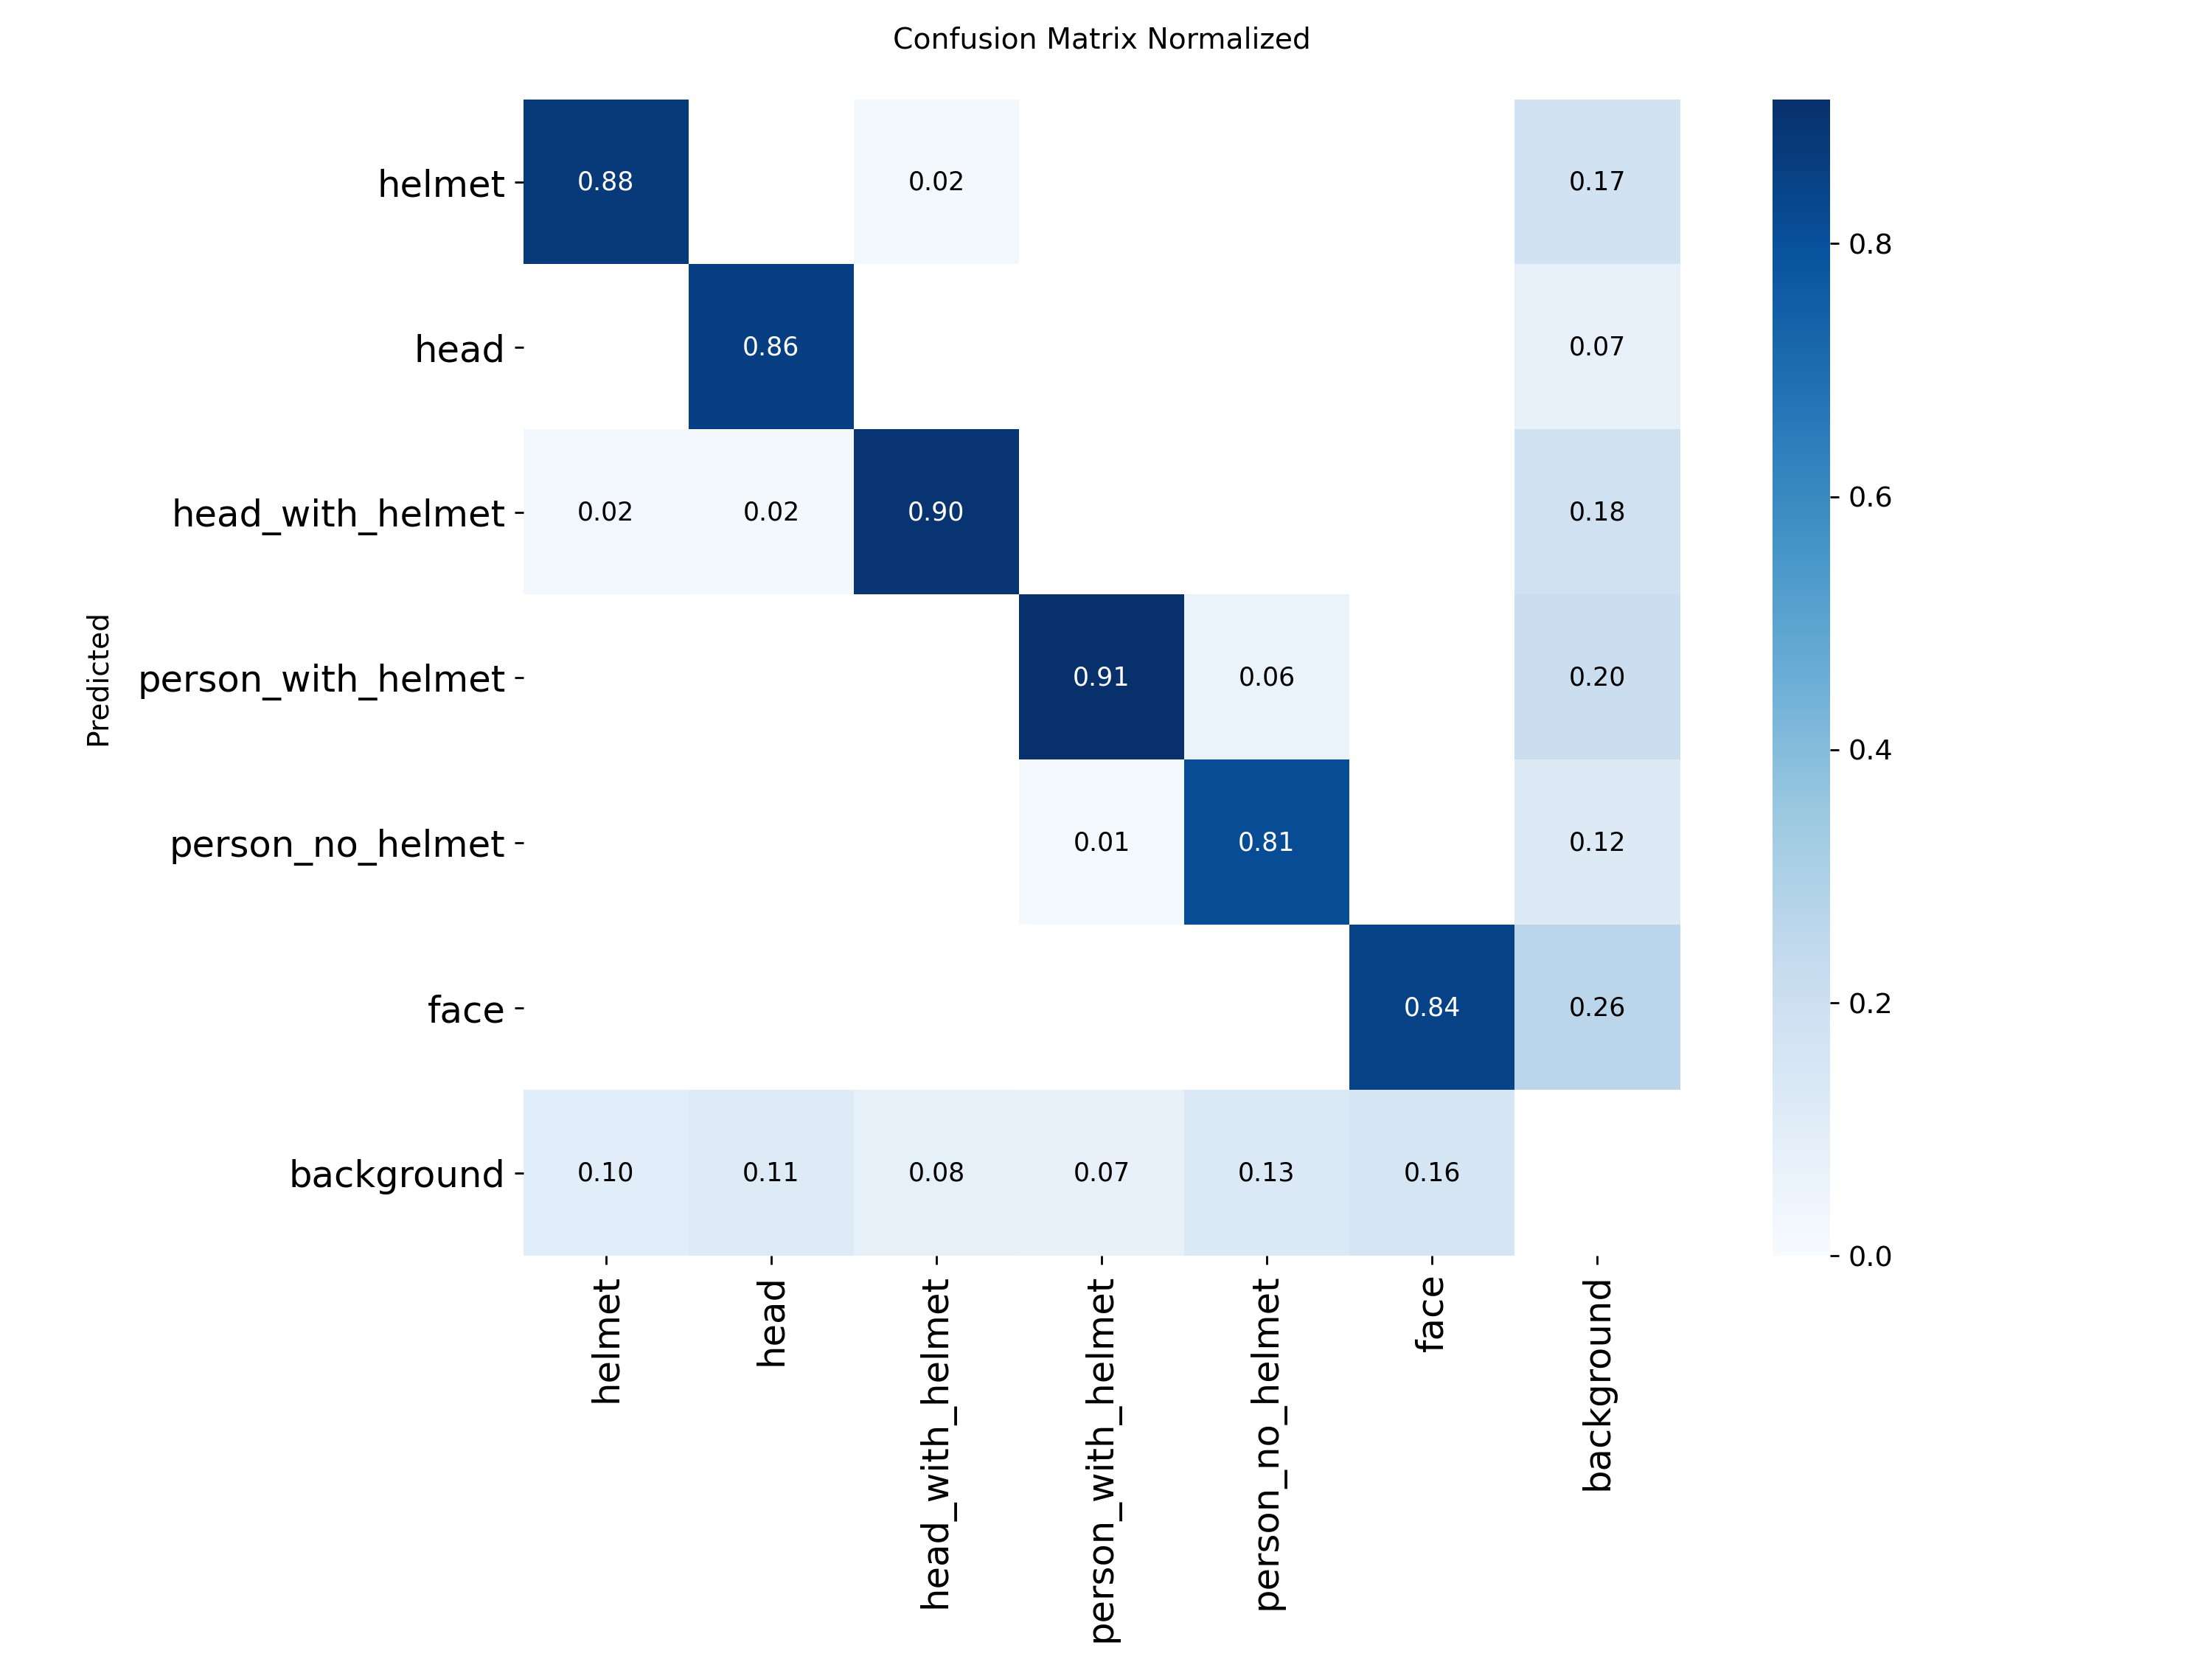

In [9]:
from IPython.display import Image

display(Image(filename=run_dir / "val_best" / "confusion_matrix_normalized.png", width=700))

## 8. Đóng gói kết quả

Nén thư mục kết quả (bỏ `last.pt`, chỉ cần khi huấn luyện tiếp) thành `M1_yolo26n_img800_results.zip`, lưu ở `/content` và trên Drive.

In [10]:
import shutil

out = ROOT / f"{RUN_NAME}_results.zip"
with zipfile.ZipFile(out, "w") as z:
    for p in run_dir.rglob("*"):
        if p.is_file() and p.name != "last.pt":
            z.write(p, p.relative_to(PROJECT))
shutil.copy(out, PROJECT)
print(f"{out.name}: {out.stat().st_size / 1e6:.1f} MB, có ở {ROOT} và {PROJECT}")

M1_yolo26n_img800_results.zip: 18.5 MB, có ở /content và /content/drive/MyDrive/DATN/runs
